## Oresund

In [17]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [18]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from helper import get_altimetry_obs, get_wl_point_obs
from helper import plot_shred_reconstruction, extract_water_level_measurements, error_mshred

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


## Load Data and Measurement

In [19]:
# folders
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/mesh_EMOD.mesh"
obs_fldr  = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)

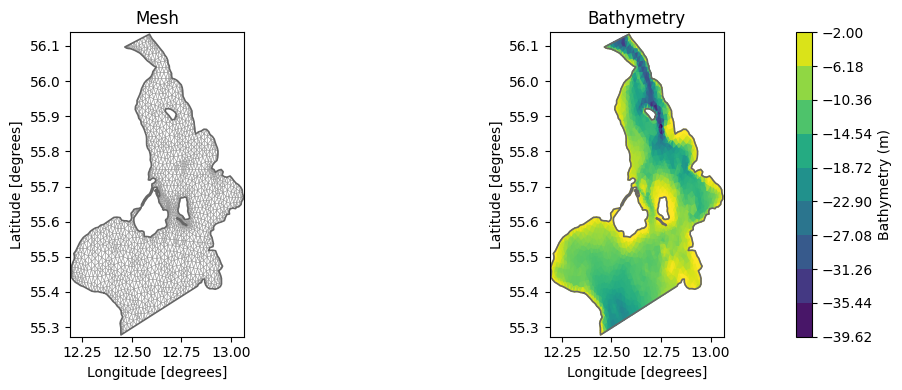

In [20]:
# plot geometry
geom = dfs.geometry

fig, axs = plt.subplots(1,2, figsize = (12,4))
geom.plot.mesh(ax=axs[0])
geom.plot(ax=axs[1])
plt.tight_layout()
plt.show()

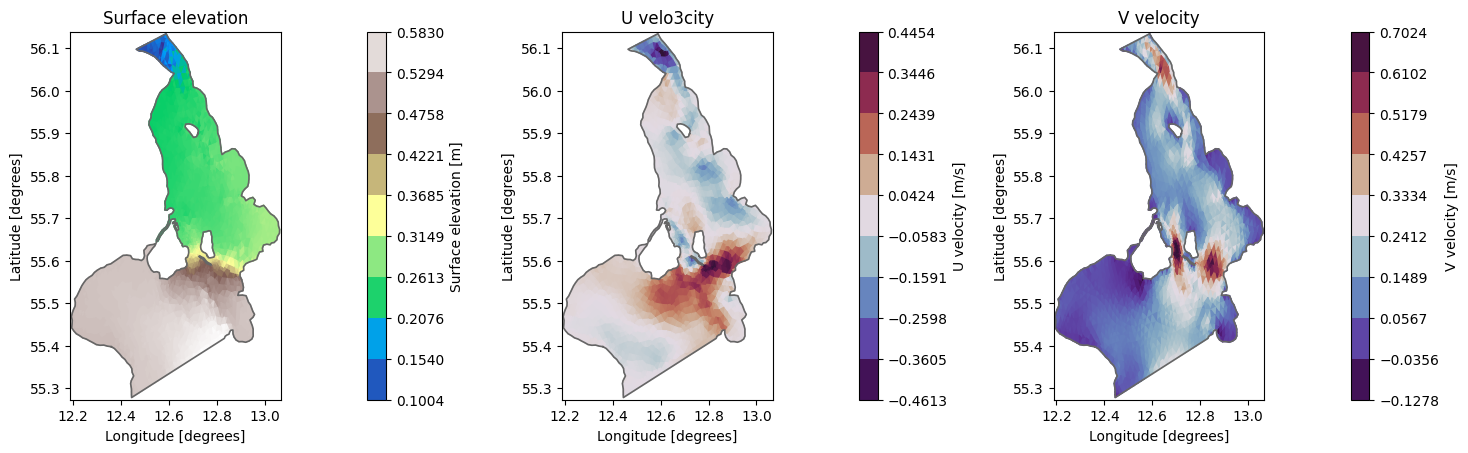

In [21]:
# plot a simulation
ds = dfs.read(time = slice("2021-01-01", "2023-12-30"))

dsH = ds["Surface elevation"]
dsU = ds["U velocity"]
dsV = ds["V velocity"]

plot_time = ds.time[-1]
fig,axs = plt.subplots(1, 3, figsize=(15,5))
dsH.sel(time=plot_time).plot(ax=axs[0], title="Surface elevation", cmap = "terrain")
dsU.sel(time=plot_time).plot(ax=axs[1], title="U velo3city", cmap = "twilight_shifted")
dsV.sel(time=plot_time).plot(ax=axs[2], title="V velocity", cmap = "twilight_shifted")
plt.tight_layout()
plt.show()


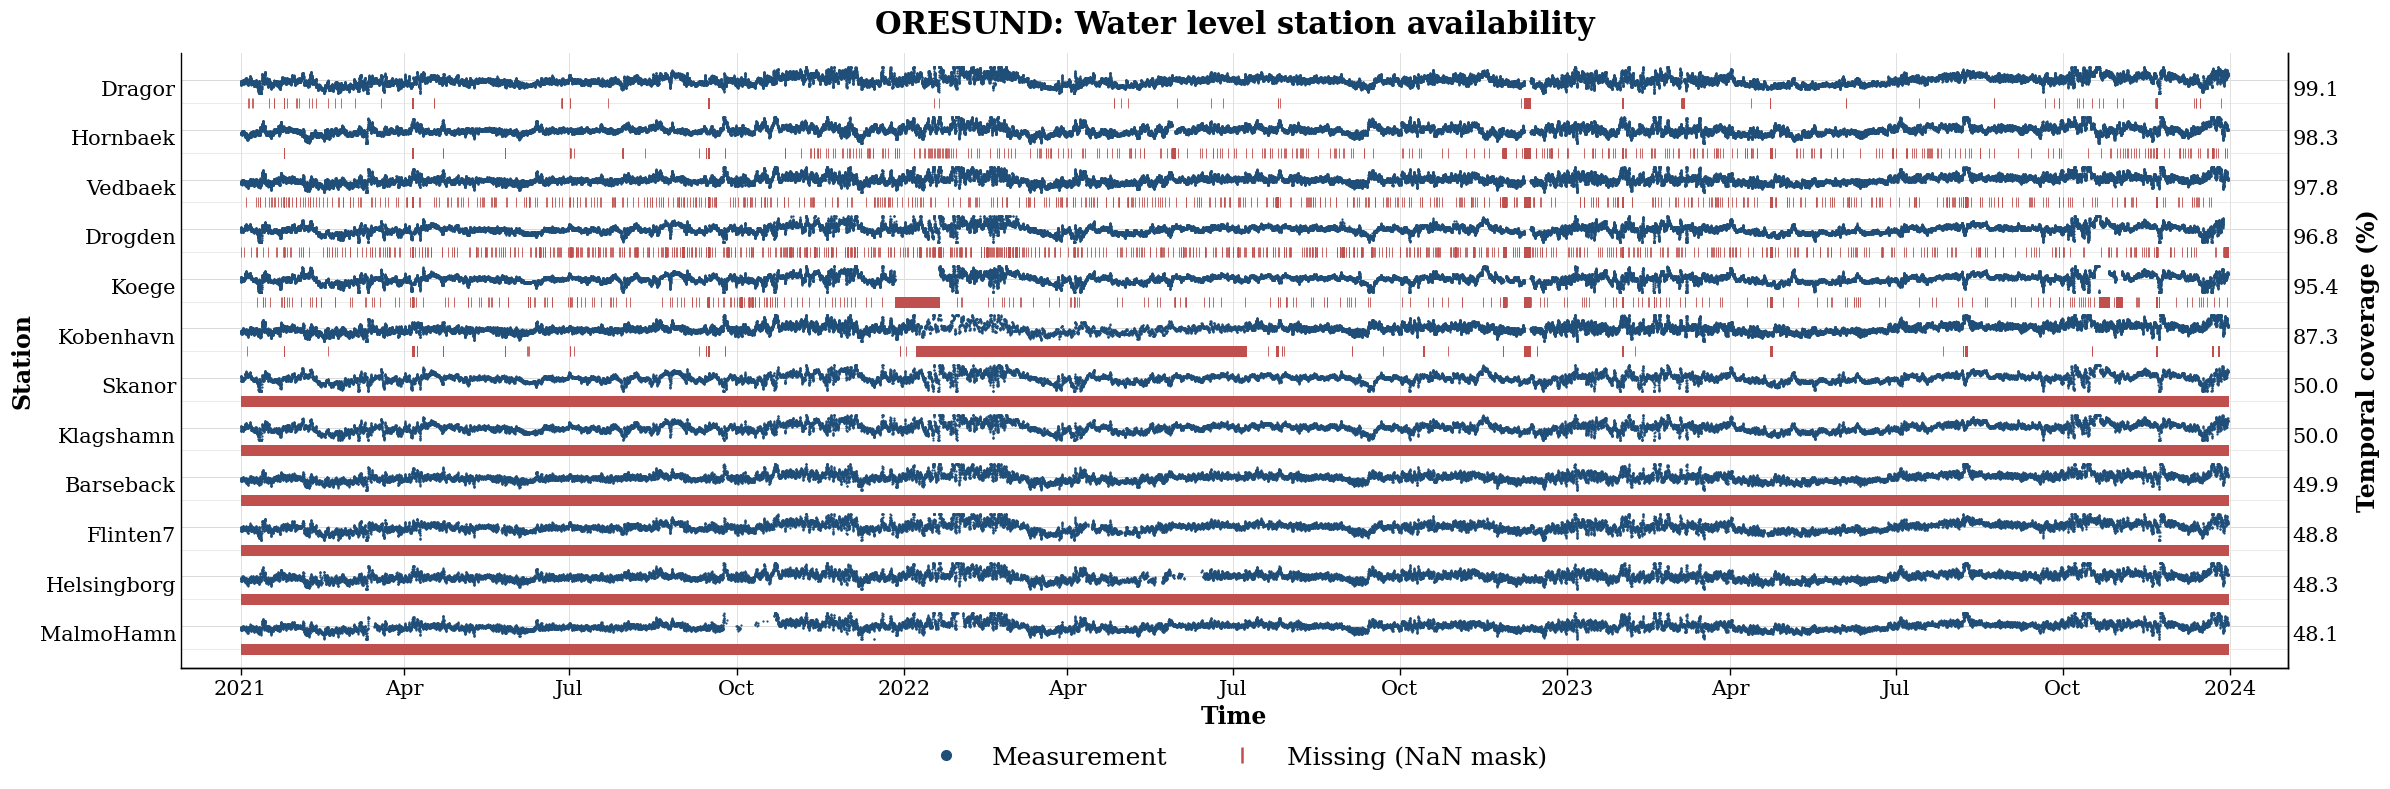

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D


def plot_station_availability(
    wllist,
    ds,
    row_h=0.26,           # half-height of the sensor trace
    sig_offset=0.14,      # sensor trace centre, above the slot centre
    mask_offset=-0.32,    # NaN mask position, below the slot centre
    marker_size=1.6,
    mask_marker_size=7.0,
    c_data="#1f4e79",     # blue: valid measurements
    c_nan="#c0504d",      # red: missing data (mask)
    figsize=(24, 8),
    font_scale=1.0,       # multiplies every font size (defaults tuned for 22x8)
    time_pad_frac=0.03,   # extra time horizon on each side, as a fraction of the span
    xlim=None,            # optional (start, end) to override the time range
    savepath=None,
    dpi=300,
):
    """
    Plot water-level station availability against the simulation timeline.

    Each station occupies one slot made of two sub-rows:
      - top: the sensor stream (blue dots, one per valid measurement);
      - bottom: a mask strip with a red tick wherever the station has no data (NaN).

    Parameters
    ----------
    wllist : list
        Observation objects with .name, .time and .values attributes.
    ds : xarray.Dataset
        Model output with a `time` coordinate.
    row_h : float
        Half-height of the sensor trace (in slot units).
    sig_offset, mask_offset : float
        Vertical position of the sensor trace / NaN mask relative to the slot centre.
    marker_size, mask_marker_size : float
        Marker sizes (points) for the sensor dots / mask ticks.
    c_data, c_nan : str
        Colours for valid / missing samples.
    figsize : tuple
        Figure size in inches.
    font_scale : float
        Global multiplier for all font sizes.
    time_pad_frac : float
        Widens the time axis by this fraction of the simulation span on each side.
    xlim : tuple or None
        Explicit (start, end) for the time axis; overrides `time_pad_frac`.
    savepath : str or None
        If given, the figure is saved there (e.g. "station_availability.pdf").
    dpi : int
        Resolution used for rasterized traces when saving.

    Returns
    -------
    fig, ax, coverage_pct_by_name
    """
    fs = lambda x: x * font_scale

    # ---- coverage against the simulation timeline ----
    model_time = pd.DatetimeIndex(ds.time)
    coverage_pct_by_name = {}
    series_by_name = {}
    for obs in wllist:
        s = pd.Series(np.asarray(obs.values).ravel(), index=pd.DatetimeIndex(obs.time))
        s = s[~s.index.duplicated()]
        s = s.reindex(model_time)                     # NaN where no data
        series_by_name[obs.name] = s
        coverage_pct_by_name[obs.name] = 100.0 * s.notna().sum() / len(model_time)

    # lowest coverage at the bottom, highest at the top
    wllist_sorted = sorted(wllist, key=lambda o: coverage_pct_by_name.get(o.name, 0.0))
    n = len(wllist_sorted)

    # ---- time axis limits (widened horizon) ----
    if xlim is not None:
        t0, t1 = pd.Timestamp(xlim[0]), pd.Timestamp(xlim[1])
    else:
        span = model_time[-1] - model_time[0]
        t0 = model_time[0] - span * time_pad_frac
        t1 = model_time[-1] + span * time_pad_frac

    # ---- paper-style plot ----
    rc = {
        "font.family": "serif",
        "font.serif": ["Times New Roman", "DejaVu Serif"],
        "mathtext.fontset": "stix",
        "axes.linewidth": 1.0,
        "xtick.direction": "out",
        "xtick.major.width": 1.0,
        "xtick.major.size": 5,
    }

    with plt.rc_context(rc):
        fig, ax = plt.subplots(figsize=figsize)

        for i, obs in enumerate(wllist_sorted):
            s = series_by_name[obs.name]
            mask = s.notna().values
            y_sig = i + sig_offset
            y_mask = i + mask_offset

            # baselines: sensor zero line and mask strip
            ax.axhline(y_sig, color="0.85", lw=0.7, zorder=0)
            ax.axhline(y_mask, color="0.92", lw=0.7, zorder=0)

            # --- sensor stream: blue dots, centred on the sub-row and scaled ---
            if mask.any():
                valid = s[mask]
                vals = valid - valid.mean()
                scale = np.percentile(np.abs(vals.values), 99)
                scale = scale if np.isfinite(scale) and scale > 0 else 1.0
                y = y_sig + np.clip(vals.values / scale, -1, 1) * row_h

                ax.plot(
                    valid.index, y,
                    linestyle="none", marker="o", ms=marker_size, mew=0,
                    color=c_data, zorder=2, rasterized=True,
                )

            # --- NaN mask: red ticks below the sensor ---
            if (~mask).any():
                ax.plot(
                    s.index[~mask], np.full((~mask).sum(), y_mask),
                    linestyle="none", marker="|", ms=mask_marker_size, mew=0.6,
                    color=c_nan, zorder=1, rasterized=True,
                )

        ax.set_ylim(-0.7, n - 0.3)
        ax.set_xlim(t0, t1)

        # readable date ticks on a wide axis
        locator = mdates.AutoDateLocator(minticks=8, maxticks=16)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

        # left labels: station name
        ax.set_yticks(range(n))
        ax.set_yticklabels([o.name for o in wllist_sorted], fontsize=fs(15))
        ax.set_ylabel("Station", fontsize=fs(17), fontweight="bold")

        # right labels: coverage %
        ax2 = ax.twinx()
        ax2.set_ylim(ax.get_ylim())
        ax2.set_yticks(range(n))
        ax2.set_yticklabels(
            [f"{coverage_pct_by_name[o.name]:.1f}" for o in wllist_sorted], fontsize=fs(15)
        )
        ax2.set_ylabel("Temporal coverage (%)", fontsize=fs(17), labelpad=12, fontweight="bold")

        ax.set_xlabel("Time", fontsize=fs(17), fontweight="bold")
        ax.tick_params(axis="x", labelsize=fs(15))
        ax.tick_params(axis="y", length=0)
        ax2.tick_params(axis="y", length=0)
        ax.grid(axis="x", color="0.88", lw=0.7)
        ax.set_axisbelow(True)
        for a in (ax, ax2):
            a.spines["top"].set_visible(False)
        ax2.spines["left"].set_visible(False)

        ax.set_title(
            "ORESUND: Water level station availability",
            fontsize=fs(22), pad=14, fontweight="bold",
        )

        # legend
        ax.legend(
            handles=[
                Line2D([0], [0], marker="o", ls="none", color=c_data, ms=7, label="Measurement"),
                Line2D([0], [0], marker="|", ls="none", color=c_nan, ms=12, mew=1.8, label="Missing (NaN mask)"),
            ],
            loc="upper center", bbox_to_anchor=(0.5, -0.09),
            ncol=2, frameon=False, fontsize=fs(18),
        )

        fig.tight_layout()
        if savepath:
            fig.savefig(savepath, bbox_inches="tight", dpi=dpi)
        plt.show()

    return fig, ax, coverage_pct_by_name


# Uso:
wllist = get_wl_point_obs()
fig, ax, cov = plot_station_availability(wllist, ds, savepath="station_availability.pdf")

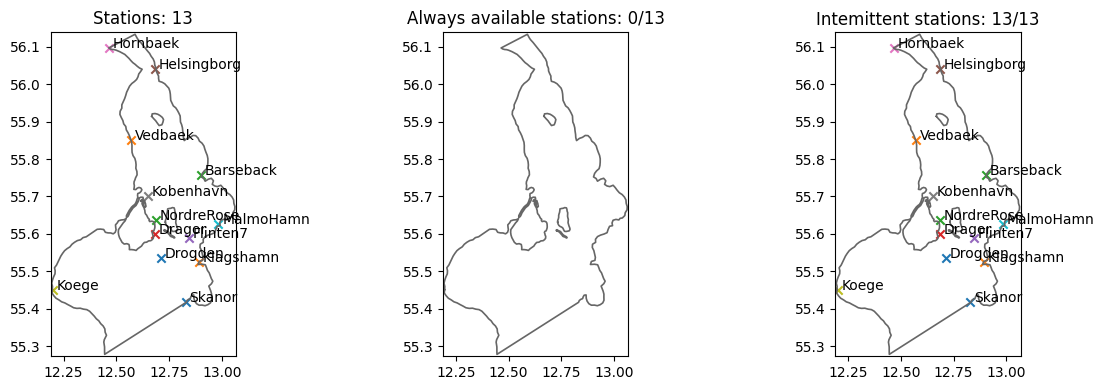

In [7]:
# Select stations with full temporal coverage

stations = []
availables = []
intermittent = []
for i in range(len(wllist)):
    stations.append(wllist[i])
    if ds.time.isin(wllist[i].time).all():
        availables.append(wllist[i])
    else:
        intermittent.append(wllist[i])

fig, axs = plt.subplots(1,3, figsize = (12,4))
ms.plotting.spatial_overview(stations, mod = msh.geometry, figsize = (5,5), ax=axs[0], title=f"Stations: {len(stations)}")
ms.plotting.spatial_overview(availables, mod = msh.geometry, figsize = (5,5), ax=axs[1], title=f"Always available stations: {len(availables)}/{len(stations)}")
ms.plotting.spatial_overview(intermittent, mod = msh.geometry, figsize = (5,5), ax=axs[2], title=f"Intemittent stations: {len(intermittent)}/{len(stations)}")

plt.tight_layout()
plt.show()


In [8]:
# Extract the values and convert to torch tensors

measurements = extract_water_level_measurements(stations, ds_time=ds.time, obs_fldr=obs_fldr)
print("\nMeasurements shape:", measurements.shape)

# Build a single mask for nodes that are valid in all output fields
surface = ds["Surface elevation"].values
u_velocity = ds["U velocity"].values
v_velocity = ds["V velocity"].values
valid_nodes = np.isfinite(surface).all(axis=0) & np.isfinite(u_velocity).all(axis=0) & np.isfinite(v_velocity).all(axis=0)

# outputs
H = torch.from_numpy(surface[:, valid_nodes].astype(np.float32, copy=False))
U = torch.from_numpy(u_velocity[:, valid_nodes].astype(np.float32, copy=False))
V = torch.from_numpy(v_velocity[:, valid_nodes].astype(np.float32, copy=False))

# inputs
measurements = torch.as_tensor(measurements, dtype=torch.float32)

# print the shape of the arrays
print("\nH shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements.shape)

# free memory
del surface, u_velocity, v_velocity, valid_nodes


Measurements shape: (52512, 13)

H shape: torch.Size([52512, 3320])
U shape: torch.Size([52512, 3320])
V shape: torch.Size([52512, 3320])
Measurements shape: torch.Size([52512, 13])
